<a href="https://colab.research.google.com/github/Kishore-Krish19/ML/blob/main/Transformer_English_French_Translation_Max_accuracy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Connect to google drive

In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/Transformer_Translation"
os.makedirs(SAVE_DIR, exist_ok=True)

STAGE1_PATH = os.path.join(
    SAVE_DIR, "stage1_best.weights.h5"
)

STAGE2_PATH = os.path.join(
    SAVE_DIR, "stage2_best.weights.h5"
)

STAGE3_PATH = os.path.join(
    SAVE_DIR, "stage3_best.weights.h5"
)

print("Stage 1:", STAGE1_PATH)
print("Stage 2:", STAGE2_PATH)
print("Stage 3:", STAGE3_PATH)

Environment Setup

In [ ]:
!pip -q install datasets tokenizers sacrebleu matplotlib

In [ ]:
import tensorflow as tf
import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Keras version: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Downloading the Dataset

In [ ]:
import os
import zipfile
import keras

url = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"

zip_path = keras.utils.get_file(
    fname="fra-eng.zip",
    origin=url,
    extract=False
)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/fra_eng")

print("Dataset downloaded successfully!")
print("Files:", os.listdir("/content/fra_eng"))

3423204/3423204 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset downloaded successfully!
Files: ['_about.txt', 'fra.txt']


Reading the dataset

In [ ]:
import pathlib

text_file = pathlib.Path("/content/fra_eng/fra.txt")

with open(text_file, encoding="utf-8") as f:
    lines = f.read().splitlines()

text_pairs = []

for line in lines:
    parts = line.split("\t")
    if len(parts) >= 2:
        english = parts[0]
        french = parts[1]
        text_pairs.append((english, french))

print("Total sentence pairs:", len(text_pairs))

print("\nFirst 5 sentence pairs:\n")

for eng, fra in text_pairs[:5]:
    print("English:", eng)
    print("French :", fra)
    print("-" * 40)

Total sentence pairs: 167130

First 5 sentence pairs:

English: Go.
French : Va !
----------------------------------------
English: Hi.
French : Salut !
----------------------------------------
English: Run!
French : Cours !
----------------------------------------
English: Run!
French : Courez !
----------------------------------------
English: Who?
French : Qui ?
----------------------------------------


Visualize dataset sentence length

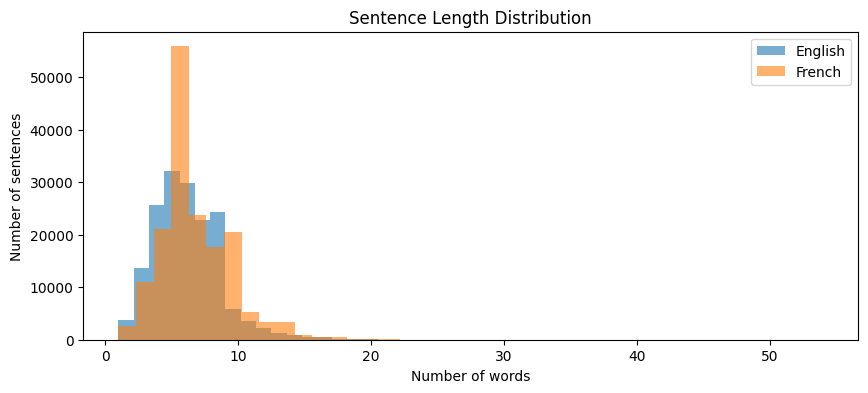

In [ ]:
import matplotlib.pyplot as plt

english_lengths = [
    len(eng.split()) for eng, fra in text_pairs
]

french_lengths = [
    len(fra.split()) for eng, fra in text_pairs
]

plt.figure(figsize=(10, 4))

plt.hist(english_lengths, bins=40, alpha=0.6, label="English")
plt.hist(french_lengths, bins=40, alpha=0.6, label="French")

plt.xlabel("Number of words")
plt.ylabel("Number of sentences")
plt.title("Sentence Length Distribution")
plt.legend()
plt.show()

3.1 Prepare and split the dataset

In [ ]:
import random

random.seed(42)

# Shuffle the complete dataset
random.shuffle(text_pairs)

# Use 30,000 sentence pairs initially
text_pairs = text_pairs[:30000]

# Add special start and end tokens to French targets
text_pairs = [
    (eng, "[start] " + fra + " [end]")
    for eng, fra in text_pairs
]

# Split: 80% train, 10% validation, 10% test
num_val = int(0.1 * len(text_pairs))
num_test = int(0.1 * len(text_pairs))

train_pairs = text_pairs[:-(num_val + num_test)]

val_pairs = text_pairs[-(num_val + num_test):-num_test]

test_pairs = text_pairs[-num_test:]

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Testing pairs:", len(test_pairs))

print("\nExample training pair:")
print(train_pairs[0])

Training pairs: 24000
Validation pairs: 3000
Testing pairs: 3000

Example training pair:
("Maybe we shouldn't do that today.", "[start] Peut-être ne devrions-nous pas faire cela aujourd'hui. [end]")
